# Where our Monte Carlo breaks down: L=4 and L=6 diagnostics
### Seed dependence and finite-budget sampling reliability

**Main finding:** unreliable finite-budget sampling is already demonstrated at
**L=4, N=48, Γ=.60, disorder60000**. The two training seeds produce substantially
different P(q): repeat-mean ⟨q²⟩ is **0.32594 versus 0.16535**, with histogram
TV **0.44798**. Both seed1 repeats and one seed0 repeat have ancestry alarms.
Agreement between the two seed0 repeats did not establish a reliable result.

The broader **L=6, N=108** evidence also demonstrates unreliable sampling.
Every fixed-guide RBM run in the completed low-field training-budget
study has an ancestry alarm. Longer training, more walkers, and feedback do not
consistently remove the problem. Improved feedback variants do help some runs;
those exceptions are included.

**Scope of the conclusion:** these results do not support a reliable-L4 /
unreliable-L6 boundary, nor failure of every run at either size. In the audited
Monte Carlo scaling campaign, L=8 and L=10 were stopped during warm-start
training, before physical measurements; this statement does not refer to RG.
Here “deep glassy” is the motivating low-field hypothesis, **not a measured phase
assignment**. The Γ=.85 and 1.00 reference runs also fail ancestry checks, so the
data do not isolate failure exclusively to the lowest fields.

All figures come from saved measurements. The L4 contrast now includes four
additional seed1 projections of archived guides, completing both seeds and
both repeats for the two displayed disorders. Raw-state analysis and notebook
generation run on AutoDL; this local notebook reads a small, hash-verified
evidence bundle and needs only NumPy, Matplotlib, and IPython.

In [1]:
%matplotlib inline
from pathlib import Path
from collections import defaultdict
import gzip, hashlib, json, os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import NullLocator
from IPython.display import display, Markdown, HTML

override = os.environ.get('MC_FAILURE_REPORT_DIR')
if override:
    evidence = Path(override)
else:
    root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p/'data/kagome').is_dir())
    evidence = root/'data/kagome/monte_carlo_failure_v1/20261105'
hashes = json.loads((evidence/'sha256.json').read_text())
if (evidence/'report.json.gz').exists():
    packed = (evidence/'report.json.gz').read_bytes()
    if 'report.json.gz' in hashes:
        assert hashlib.sha256(packed).hexdigest() == hashes['report.json.gz']
    payload = gzip.decompress(packed)
else:
    payload = (evidence/'report.json').read_bytes()
assert hashlib.sha256(payload).hexdigest() == hashes['report.json']
report = json.loads(payload)
runs = report['runs']
thresholds = report['thresholds']
plt.rcParams.update({'figure.dpi': 115, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
COLORS = {'seed0':'#2166ac', 'seed1':'#b2182b', 'jastrow':'#d28b26',
          'rbm_2':'#246bb0', 'baseline':'#ae3a46', 'robust':'#168476',
          'curriculum_pcd':'#168476', 'direct_pcd':'#7045a0', 'direct_reset':'#c16c24'}
def table(headers, rows):
    lines = ['| '+' | '.join(headers)+' |', '| '+' | '.join(['---']*len(headers))+' |']
    lines += ['| '+' | '.join(str(v) for v in row)+' |' for row in rows]
    display(Markdown('\n'.join(lines)))
def select(campaign=None, **criteria):
    return [r for r in runs if (campaign is None or r['campaign']==campaign)
            and all(r['task'].get(k)==v for k,v in criteria.items())]
def show(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)
def stamp(ax):
    ax.grid(alpha=.18)
print('Verified evidence snapshot:', report['snapshot_utc'])
print('Saved measurement records:', len(runs), '| feedback stints:',
      sum(len(t['rows']) for t in report['training']))
print('No simulations are launched by this notebook.')

Verified evidence snapshot: 2026-11-05T08:40:14.071530+00:00
Saved measurement records: 320 | feedback stints: 384
No simulations are launched by this notebook.


## 1. What counts as failure?

The periodic kagome Hamiltonian is
$$H=\sum_{\langle ij\rangle}K_{ij}Z_iZ_j-h\sum_i Z_i-\Gamma\sum_iX_i,$$
with $N=3L^2$, $h=.15$, iid $K_{ij}\sim U(.5,1.5)$, and stored $J=-K$.
Disorder generation uses `SeedSequence([20261027,L,sample_id,1])`.

- **Ancestry failure:** descendant ESS <8 **or** largest lineage >.5 in any
  population/forward-walking cycle. Counts are descriptive; cycles and
  descendants are not independent disorder samples.
- **Finite-budget inconsistency:** differences above the existing engineering
  screens: energy/site .001, $\langle q^2\rangle$ .01, histogram total variation
  .05, or connected-spectrum difference above max(10% of larger magnitude,.001).
  These are not statistical significance tests. Agreement cannot establish
  convergence without resolved ancestry and sufficiently precise independent checks.
- **Execution failure:** a recorded exception, distinct from either criterion above.

The main fixed-guide grid is two fixed disorders (60000/60001), both RBM seeds
(0/1), 400/1600/4000 target-field updates, and two independent projection repeats.
Each run uses four independently branching 512-walker populations, equilibration16,
forward time16, and eight cycles. Low fields .55/.60/.65/.70 give 96 runs;
.85/1.00 references give 48. No energy-based seed selection is used in this grid.

**Uncertainty convention:** no error bars on individual-disorder curves.
Repeats and seeds remain separate; no walker-, repeat-, or seed-based SE is
presented as disorder uncertainty. These two diagnostic disorders are not the
planned eight-disorder ensemble. No pooled disorder-mean inference is made.

In [2]:
labels = {'fixed_low':'L6 low-field budget grid (other 14 contexts)',
          'fixed_extension':'L6 Γ=.55 / disorder60000 budget extension',
          'reference_fields':'L6 Γ=.85/1.00 reference grid',
          'ancestry_controls':'L6 prespecified population/forward controls',
          'production_audits':'Repaired production snapshot: L4 and L6',
          'feedback_original':'L6 original six-stint feedback pilot',
          'feedback_frontier':'L6 baseline / robust feedback, stints6/12',
          'pcd_curriculum':'L6 reset / PCD / curriculum, stints21/24',
          'small_exact':'L2 exact-reference feedback validation',
          'strong_field':'Γ=4 strong-field controls: L2 and L6'}
table(['Saved campaign','Runs','Runs with ancestry alarm'],
      [(labels[c['name']],c['runs'],f"{c['alarms']}/{c['runs']}") for c in report['campaigns']])
table(['Size','Completed frontier training stints','New physical measurements','Saved status'],
      [(c['L'],c['training_stints'],c['new_measurements'],
        'User-stopped during warm start; unmeasured' if 'user_stop.json' in c['metadata']
        else c['metadata']['status.json']['record']['state']) for c in report['size_coverage']])
print('The L6 frontier also reuses',len(report['reused_controls']),
      'fixed-guide controls, linked by raw hash and not counted as new measurements.')

| Saved campaign | Runs | Runs with ancestry alarm |
| --- | --- | --- |
| L6 low-field budget grid (other 14 contexts) | 84 | 84/84 |
| L6 Γ=.55 / disorder60000 budget extension | 12 | 12/12 |
| L6 Γ=.85/1.00 reference grid | 48 | 48/48 |
| L6 prespecified population/forward controls | 10 | 9/10 |
| Repaired production snapshot: L4 and L6 | 50 | 23/50 |
| L6 original six-stint feedback pilot | 8 | 8/8 |
| L6 baseline / robust feedback, stints6/12 | 32 | 29/32 |
| L6 reset / PCD / curriculum, stints21/24 | 48 | 38/48 |
| L2 exact-reference feedback validation | 4 | 0/4 |
| Γ=4 strong-field controls: L2 and L6 | 24 | 0/24 |

| Size | Completed frontier training stints | New physical measurements | Saved status |
| --- | --- | --- | --- |
| 6 | 96 | 32 | completed_unqualified |
| 8 | 0 | 0 | User-stopped during warm start; unmeasured |
| 10 | 0 | 0 | User-stopped during warm start; unmeasured |

The L6 frontier also reuses 8 fixed-guide controls, linked by raw hash and not counted as new measurements.


## 2. Healthy-looking weights hide a collapsed ancestry

For descendant counts $n_a$ and population $W$,
$$N_{\rm eff}^{\rm ancestry}=\frac{W^2}{\sum_a n_a^2},\qquad
f_{\max}=\frac{\max_a n_a}{W}.$$
The one-step branching-weight ESS does not measure how many different ancestors
survive the *whole* forward-walking interval. These plots show every saved
population/cycle for the prespecified Γ=.55, disorder60000 **main** audits.
Their selected production training seed is 1 for both guide families; this is
a separate campaign from the all-seed budget study.

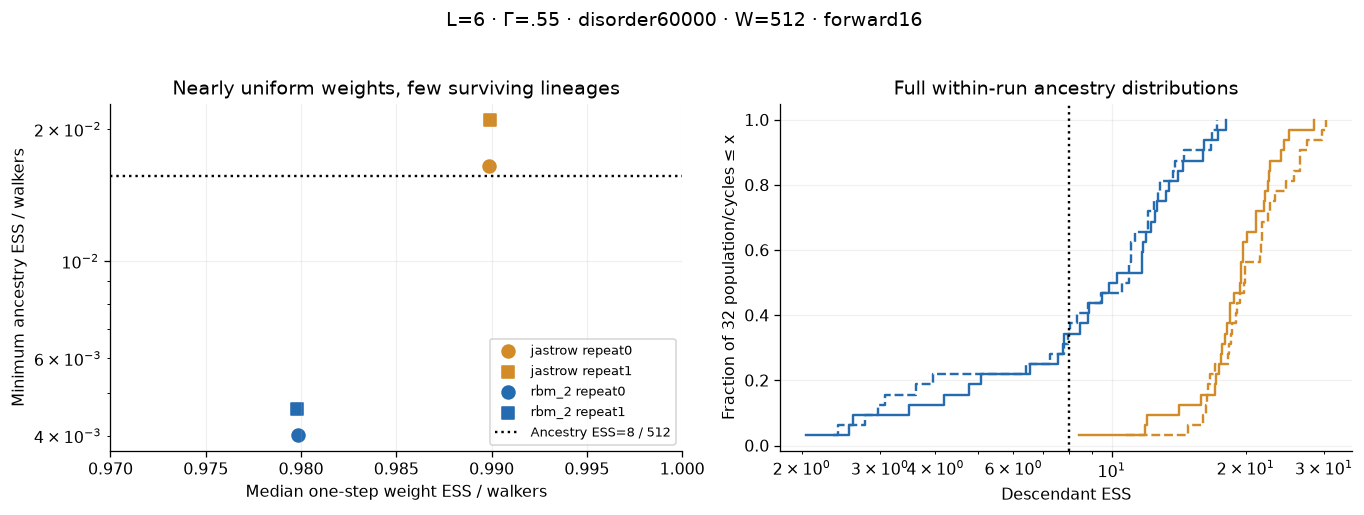

| Guide | Repeat | Median weight ESS | Minimum ancestry ESS | Alarmed population/cycles |
| --- | --- | --- | --- | --- |
| jastrow | 0 | 506.8/512 | 8.44 | 0/32 |
| jastrow | 1 | 506.8/512 | 10.75 | 0/32 |
| rbm_2 | 0 | 501.7/512 | 2.05 | 11/32 |
| rbm_2 | 1 | 501.7/512 | 2.35 | 11/32 |

In [3]:
audit_main = sorted(select('production_audits',L=6,gamma=.55,sample_id=60000,audit='main'),
                    key=lambda r:(r['task']['kind'],r['task']['repeat']))
assert len(audit_main)==4
fig,axes=plt.subplots(1,2,figsize=(12,4.3))
for r in audit_main:
    t=r['task'];color=COLORS[t['kind']];marker=['o','s'][t['repeat']]
    axes[0].scatter(r['weight_ess_fraction_median'],r['descendant_ess_min']/t['walkers'],
                    color=color,marker=marker,s=65,label=f"{t['kind']} repeat{t['repeat']}")
    values=np.sort(np.array(r['descendant_ess']).ravel())
    axes[1].step(values,np.arange(1,len(values)+1)/len(values),where='post',
                 color=color,ls=['-','--'][t['repeat']])
axes[0].axhline(8/512,color='black',ls=':',label='Ancestry ESS=8 / 512')
axes[0].set(xlabel='Median one-step weight ESS / walkers',ylabel='Minimum ancestry ESS / walkers',
            yscale='log',xlim=(.97,1.0),title='Nearly uniform weights, few surviving lineages')
axes[0].legend(fontsize=8)
axes[1].axvline(8,color='black',ls=':')
axes[1].set(xscale='log',xlabel='Descendant ESS',ylabel='Fraction of 32 population/cycles ≤ x',
            title='Full within-run ancestry distributions')
for ax in axes:stamp(ax)
fig.suptitle('L=6 · Γ=.55 · disorder60000 · W=512 · forward16',y=1.03)
show(fig)
table(['Guide','Repeat','Median weight ESS','Minimum ancestry ESS','Alarmed population/cycles'],
      [(r['task']['kind'],r['task']['repeat'],f"{r['weight_ess_quantiles'][2]:.1f}/512",
        f"{r['descendant_ess_min']:.2f}",f"{r['alarmed_population_cycles']}/{r['population_cycles']}")
       for r in audit_main])

The RBM main runs have median weight ESS ≈502/512, yet minimum descendant ESS
≈2 and 11/32 alarmed population/cycles in each repeat. Jastrow passes these
particular main-run ancestry thresholds. This is evidence of a guide- and
protocol-dependent reliability problem, not failure of every L6 simulation.

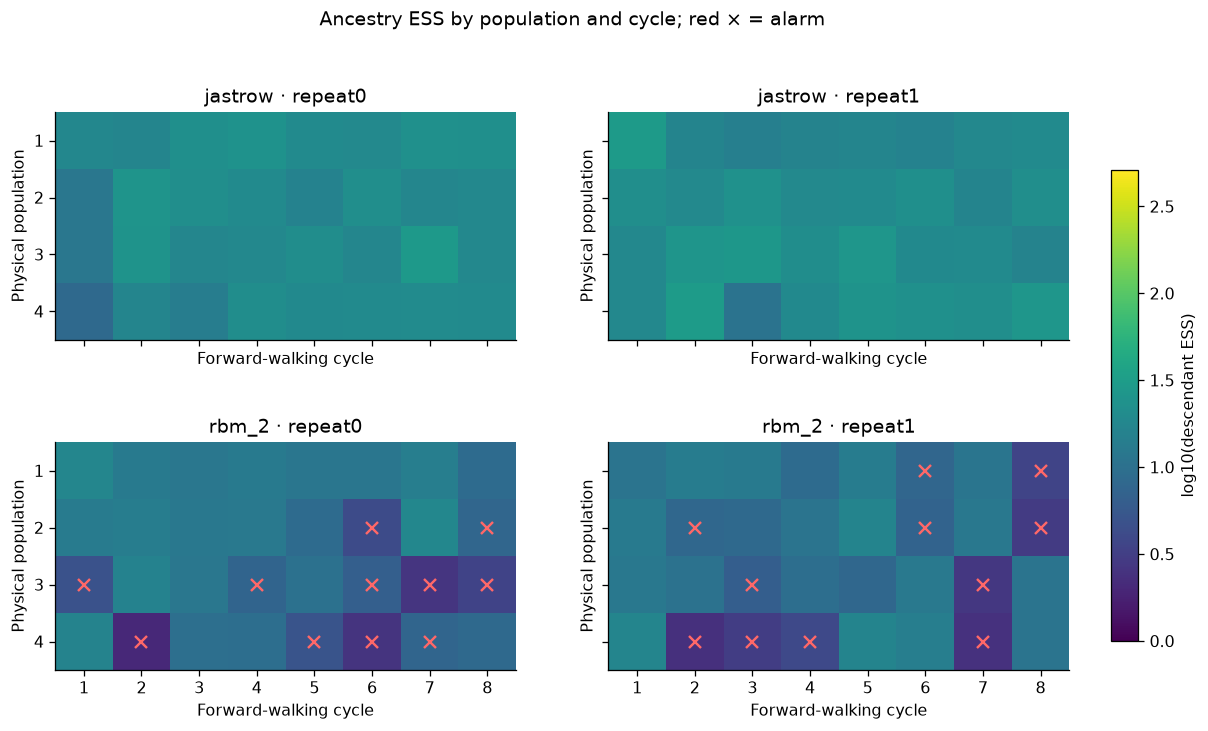

In [4]:
fig,axes=plt.subplots(2,2,figsize=(12,6.3),sharex=True,sharey=True)
for ax,r in zip(axes.flat,audit_main):
    values=np.asarray(r['descendant_ess']).T
    im=ax.imshow(np.log10(values),vmin=0,vmax=np.log10(512),aspect='auto',cmap='viridis')
    alarms=(values<8)|(np.asarray(r['largest_lineage']).T>.5)
    for pop,cycle in zip(*np.where(alarms)):
        ax.plot(cycle,pop,'x',color='#ff6868',ms=8,mew=1.5)
    ax.set(title=f"{r['task']['kind']} · repeat{r['task']['repeat']}",
           xticks=range(8),xticklabels=range(1,9),yticks=range(4),yticklabels=range(1,5),
           xlabel='Forward-walking cycle',ylabel='Physical population')
fig.suptitle('Ancestry ESS by population and cycle; red × = alarm',y=1.02)
fig.subplots_adjust(right=.86,hspace=.45,wspace=.2)
cax=fig.add_axes([.89,.15,.02,.65]);cb=fig.colorbar(im,cax=cax)
cb.set_label('log10(descendant ESS)')
plt.show();plt.close(fig)

## 3. More walkers and longer projection do not automatically fix it

All four saved audit settings for Γ=.55/disorder60000 are displayed.
`time` doubles **both equilibration and forward time** (16→32); it does not
isolate forward-time dependence. `population` doubles W (512→1024);
`start` uses uniform rather than guide initialization. Each point is a full
repeat, not an uncertainty estimate.

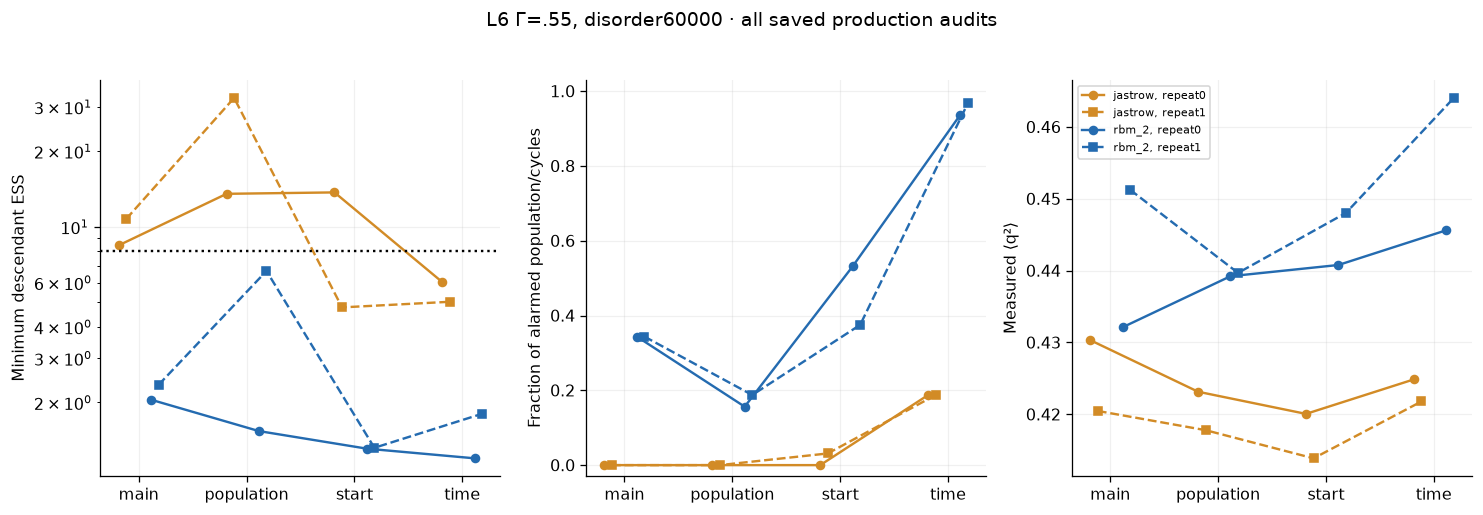

| Γ | Seed | W | Equil | Forward | Repeat | Minimum ESS | Max lineage | Alarm |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0.55 | 0 | 512 | 16.0 | 8.0 | 0 | 8.19 | 0.289 | False |
| 0.55 | 0 | 512 | 16.0 | 8.0 | 1 | 3.04 | 0.566 | True |
| 0.55 | 0 | 512 | 16.0 | 16.0 | 0 | 2.29 | 0.648 | True |
| 0.55 | 0 | 512 | 16.0 | 16.0 | 1 | 1.10 | 0.955 | True |
| 0.55 | 0 | 2048 | 16.0 | 16.0 | 0 | 3.34 | 0.540 | True |
| 0.55 | 0 | 2048 | 16.0 | 16.0 | 1 | 2.00 | 0.705 | True |
| 0.6 | 0 | 512 | 16.0 | 8.0 | 0 | 2.08 | 0.686 | True |
| 0.6 | 0 | 512 | 16.0 | 8.0 | 1 | 2.76 | 0.584 | True |
| 0.6 | 0 | 512 | 16.0 | 16.0 | 0 | 1.19 | 0.914 | True |
| 0.6 | 0 | 512 | 16.0 | 16.0 | 1 | 1.31 | 0.871 | True |

In [5]:
audits=['main','population','start','time']
rows=select('production_audits',L=6,gamma=.55,sample_id=60000)
assert len(rows)==16
fig,axes=plt.subplots(1,3,figsize=(13,4.3))
for kind,offset in [('jastrow',-.15),('rbm_2',.15)]:
    for repeat in [0,1]:
        chosen=[next(r for r in rows if r['task']['kind']==kind and r['task']['audit']==a
                     and r['task']['repeat']==repeat) for a in audits]
        x=np.arange(4)+offset+(repeat-.5)*.07
        for ax,values in zip(axes,[[r['descendant_ess_min'] for r in chosen],
                                  [r['alarmed_population_cycles']/r['population_cycles'] for r in chosen],
                                  [r['record']['q2'] for r in chosen]]):
            ax.plot(x,values,['o-','s--'][repeat],color=COLORS[kind],ms=5,
                    label=f'{kind}, repeat{repeat}')
axes[0].axhline(8,color='black',ls=':');axes[0].set(yscale='log',ylabel='Minimum descendant ESS')
axes[1].set(ylabel='Fraction of alarmed population/cycles',ylim=(-.03,1.03))
axes[2].set(ylabel='Measured ⟨q²⟩');axes[2].legend(fontsize=7)
for ax in axes:ax.set(xticks=range(4),xticklabels=audits);stamp(ax)
fig.suptitle('L6 Γ=.55, disorder60000 · all saved production audits',y=1.03)
show(fig)
extra=sorted(select('ancestry_controls'),key=lambda r:(r['task']['gamma'],r['task']['walkers'],r['task']['forward'],r['task']['repeat']))
table(['Γ','Seed','W','Equil','Forward','Repeat','Minimum ESS','Max lineage','Alarm'],
      [(r['task']['gamma'],r['task']['training_seed'],r['task']['walkers'],r['task']['equil'],
        r['task']['forward'],r['task']['repeat'],f"{r['descendant_ess_min']:.2f}",
        f"{r['largest_lineage_max']:.3f}",r['record']['ancestry_alarm']) for r in extra])

The dedicated ancestry study uses **seed0**, so its W=2048 results are not
appended to the production seed1 curves as a matched population sequence.
Nine of its ten runs alarm; one passes. Shorter forward time can improve
ancestry while retaining projection bias. Passing the genealogy threshold
alone is insufficient for a ground-state result.

## 4. The low-field budget study: seed dependence survives more training

Both disorders, both seeds, both repeats, and all three training milestones
are visible. Each panel is one fixed disorder. All 96 plotted runs alarm.
The 1600/4000-update continuations preserve optimizer, chains, and RNG;
matched cross-budget RNG does not make budgets independent replicates.

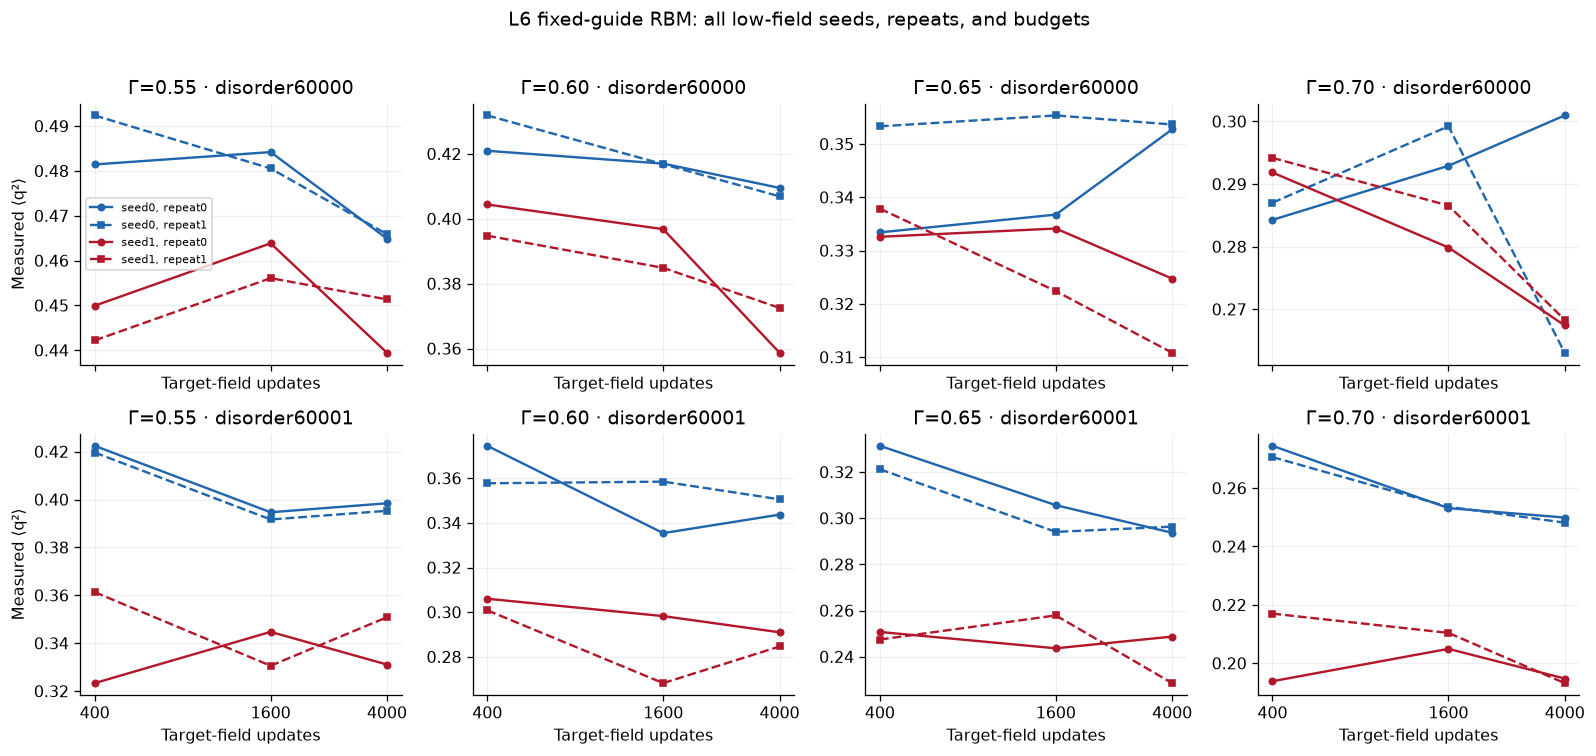

In [6]:
budget_runs=[r for r in runs if r['campaign'] in ['fixed_low','fixed_extension','reference_fields']]
fields=[.55,.60,.65,.70]
fig,axes=plt.subplots(2,4,figsize=(14,6.4),sharex=True)
for i,disorder in enumerate([60000,60001]):
    for j,gamma in enumerate(fields):
        ax=axes[i,j]
        for seed in [0,1]:
            for repeat in [0,1]:
                rows=sorted([r for r in budget_runs if r['task']['sample_id']==disorder
                             and r['task']['gamma']==gamma and r['task']['training_seed']==seed
                             and r['task']['repeat']==repeat],key=lambda r:r['target_updates'])
                assert [r['target_updates'] for r in rows]==[400,1600,4000]
                ax.plot([r['target_updates'] for r in rows],[r['record']['q2'] for r in rows],
                        ['o-','s--'][repeat],color=COLORS[f'seed{seed}'],ms=4,
                        label=f'seed{seed}, repeat{repeat}')
        ax.set(title=f'Γ={gamma:.2f} · disorder{disorder}',xscale='log',xticks=[400,1600,4000],
               xticklabels=['400','1600','4000'],xlabel='Target-field updates')
        ax.xaxis.set_minor_locator(NullLocator())
        if j==0:ax.set_ylabel('Measured ⟨q²⟩')
        stamp(ax)
axes[0,0].legend(fontsize=7)
fig.suptitle('L6 fixed-guide RBM: all low-field seeds, repeats, and budgets',y=1.02)
show(fig)

### The distribution changes, not just a summary statistic
At the prespecified Γ=.60/400-update baseline, plot the full discrete
overlap probability **mass** for both seeds. Solid/dashed lines distinguish
repeats; these are not confidence bands. Each panel remains one disorder.

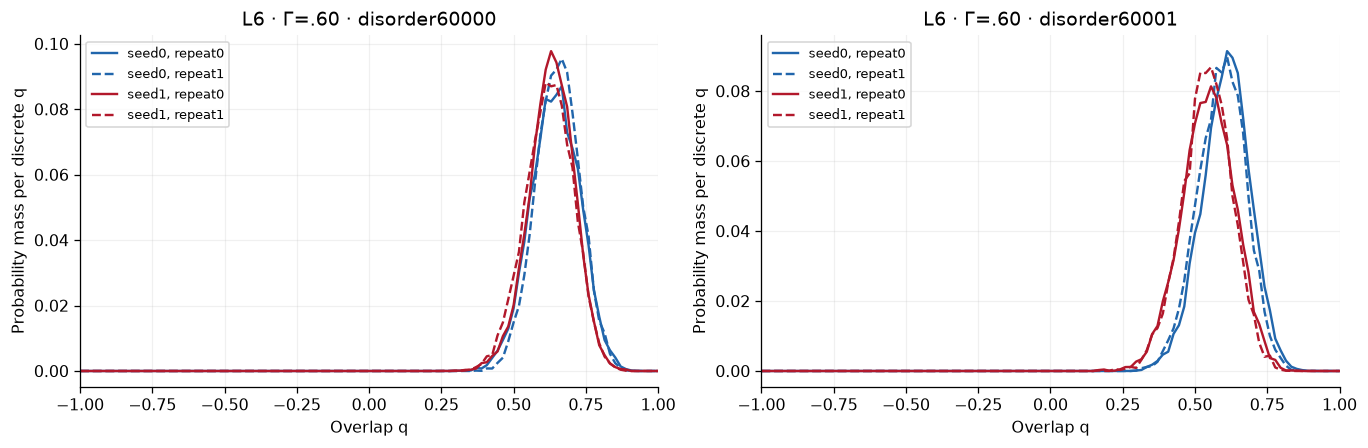

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,disorder in zip(axes,[60000,60001]):
    for seed in [0,1]:
        for repeat in [0,1]:
            r=next(r for r in budget_runs if r['task']['gamma']==.6 and r['task']['sample_id']==disorder
                   and r['target_updates']==400 and r['task']['training_seed']==seed and r['task']['repeat']==repeat)
            ax.plot(r['record']['q_grid'],r['record']['mass'],color=COLORS[f'seed{seed}'],
                    ls=['-','--'][repeat],label=f'seed{seed}, repeat{repeat}')
    ax.set(xlabel='Overlap q',ylabel='Probability mass per discrete q',
           title=f'L6 · Γ=.60 · disorder{disorder}',xlim=(-1,1))
    stamp(ax);ax.legend(fontsize=8)
show(fig)

### L=4 contrast: both training seeds with matched projection settings

These are **eight repaired L4 measurements** for Γ=.60 and disorders60000/60001:
**training seeds0 and1**, each with two independent projection repeats.
**Blue=seed0, red=seed1; solid=repeat0, dashed=repeat1.** The original four seed0
results are retained, and four missing seed1 projections were completed using
the existing trained checkpoints. Both seeds now appear regardless of their
frozen energy or ancestry outcome. No guide was retrained for this addition.

| Setting | L4 contrast | L6 panels above |
| --- | --- | --- |
| Sites | 48 | 108 |
| Hamiltonian distribution | h=.15, K∼U(.5,1.5), periodic kagome | Same |
| Guide | RBM α=2 | Same |
| Guide curriculum | 1.50→.75→.60, 400 updates per stage | Same |
| Training sampler | 256 chains, 8 temperatures, 2 sweeps/update | Same |
| Adam learning rate | **.01** | **.001** |
| Projection | 4×512 walkers, guide start, equil16, forward16, δ=.1, 8 cycles | Same |
| Projection repeats | 0 and 1 | 0 and 1 |
| Measured training seeds | **0 and 1, both retained** | **0 and 1, both retained** |
| Numerical implementation | Repaired `log_weight_v1` | Matching numerical source hashes |

**The training learning rates still differ across sizes (.01 versus .001),**
so this is not a size-only experiment. Seed0 was originally selected by lower
frozen energy; that selection no longer excludes seed1 from these panels.
The same disorder ID across sizes does not imply identical bonds: the RNG seed
includes L. All repeats are displayed individually, without error bars.

Verified L4 supplement: 2026-11-05T11:13:57.277907+00:00
Eight measurements: original seed0 + new seed1 projections. SHA256: 2a61f0bac1e62a5a95973a78f76771a95d37b29bc2c5d160b9c38aafb3828762


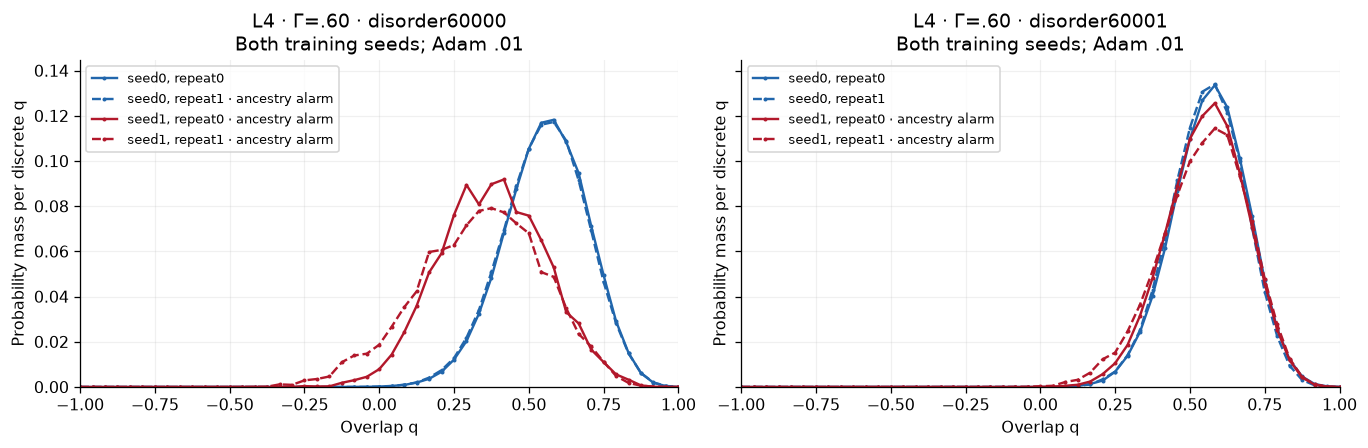

| L4 disorder | Seed | Repeat | ⟨q²⟩ | Minimum ancestry ESS | Maximum lineage | Alarm |
| --- | --- | --- | --- | --- | --- | --- |
| 60000 | 0 | 0 | 0.327740 | 12.15 | 0.236 | False |
| 60000 | 0 | 1 | 0.324134 | 1.98 | 0.705 | True |
| 60000 | 1 | 0 | 0.173344 | 1.02 | 0.990 | True |
| 60000 | 1 | 1 | 0.157360 | 1.00 | 1.000 | True |
| 60001 | 0 | 0 | 0.336361 | 11.01 | 0.268 | False |
| 60001 | 0 | 1 | 0.328359 | 11.89 | 0.244 | False |
| 60001 | 1 | 0 | 0.325398 | 2.06 | 0.691 | True |
| 60001 | 1 | 1 | 0.319761 | 2.48 | 0.627 | True |

In [8]:
l4_evidence = evidence/'l4_two_seed_contrast'
l4_hashes = json.loads((l4_evidence/'sha256.json').read_text())
l4_packed = (l4_evidence/'report.json.gz').read_bytes()
assert hashlib.sha256(l4_packed).hexdigest() == l4_hashes['report.json.gz']
l4_payload = gzip.decompress(l4_packed)
assert hashlib.sha256(l4_payload).hexdigest() == l4_hashes['report.json']
l4_report = json.loads(l4_payload)
assert l4_report['baseline_report_sha256'] == hashes['report.json']
l4_runs = sorted(l4_report['runs'], key=lambda r:(r['task']['sample_id'],
                                                 r['task']['training_seed'],r['task']['repeat']))
assert {(r['task']['sample_id'],r['task']['training_seed'],r['task']['repeat']) for r in l4_runs} == {
    (d,seed,repeat) for d in [60000,60001] for seed in [0,1] for repeat in [0,1]}
assert len(l4_runs) == len({r['raw_sha256'] for r in l4_runs}) == 8
for r in l4_runs:
    assert r['task']['L'] == 4 and r['task']['gamma'] == .6
    assert {'training_checkpoint_hash_link','L6_projection_protocol_match',
            'L6_numerical_source_hash_match',
            'full_histogram_reconstruction_from_raw_tags_counts'} <= set(r['checks'])
    np.testing.assert_allclose(np.sum(r['record']['mass']),1,atol=1e-12)
print('Verified L4 supplement:',l4_report['snapshot_utc'])
print('Eight measurements: original seed0 + new seed1 projections. SHA256:',l4_hashes['report.json'])
fig,axes=plt.subplots(1,2,figsize=(12,4),sharey=True)
for ax,disorder in zip(axes,[60000,60001]):
    chosen=[r for r in l4_runs if r['task']['sample_id']==disorder]
    for r in chosen:
        seed=r['task']['training_seed']; repeat=r['task']['repeat']; alarm=r['record']['ancestry_alarm']
        ax.plot(r['record']['q_grid'],r['record']['mass'],color=COLORS[f'seed{seed}'],
                ls=['-','--'][repeat],marker='.',ms=3,
                label=f'seed{seed}, repeat{repeat}'+(' · ancestry alarm' if alarm else ''))
    ax.set(xlabel='Overlap q',ylabel='Probability mass per discrete q',xlim=(-1,1),ylim=(0,None),
           title=f'L4 · Γ=.60 · disorder{disorder}\nBoth training seeds; Adam .01')
    stamp(ax);ax.legend(fontsize=8)
axes[0].set_ylim(0,1.08*max(max(r['record']['mass']) for r in l4_runs))
assert all(max(line.get_ydata()) < ax.get_ylim()[1] for ax in axes for line in ax.lines)
show(fig)
table(['L4 disorder','Seed','Repeat','⟨q²⟩','Minimum ancestry ESS','Maximum lineage','Alarm'],
      [(r['task']['sample_id'],r['task']['training_seed'],r['task']['repeat'],
        f"{r['record']['q2']:.6f}",f"{r['descendant_ess_min']:.2f}",
        f"{r['largest_lineage_max']:.3f}",r['record']['ancestry_alarm']) for r in l4_runs])

### L4 versus L6 on a common vertical scale

The q-grid spacing changes with system size: Δq=2/N is **1/24 at L4** and
**1/54 at L6**. Direct probability-mass peak heights therefore have different
bin widths. Here each native-grid mass is divided by its own Δq, and all panels
share axes. This is a **density-scaled display of discrete probabilities**, not
smoothing, rebinning, or an assumed continuous density. Every saved repeat is
retained. The tables distinguish within-seed repeat differences from between-seed
differences of descriptive repeat means; neither is an uncertainty estimate.

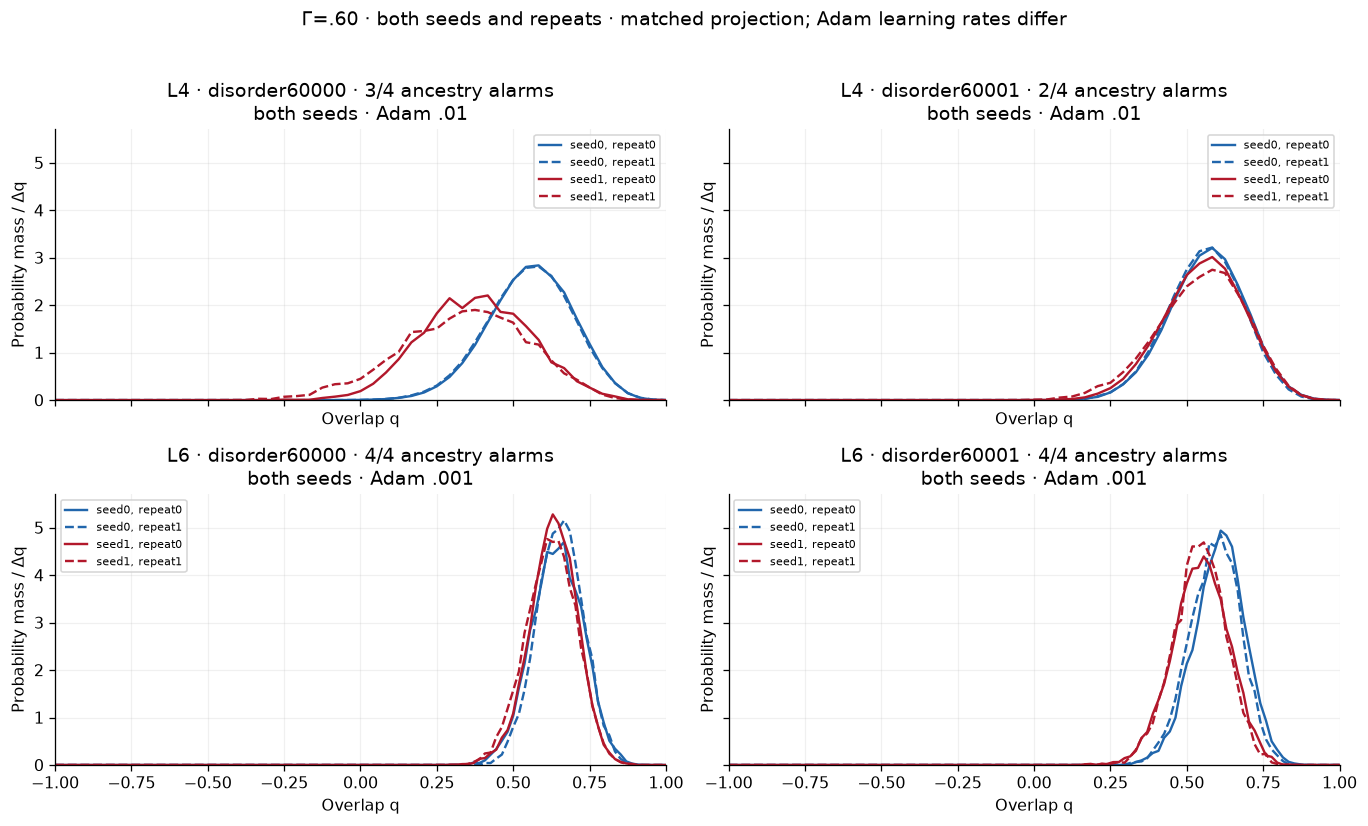

| L | Disorder | Training seed | Repeat TV | Absolute Δ⟨q²⟩ | Alarms / 2 repeats |
| --- | --- | --- | --- | --- | --- |
| 4 | 60000 | 0 | 0.01134 | 0.00361 | 1/2 |
| 4 | 60000 | 1 | 0.09724 | 0.01598 | 2/2 |
| 4 | 60001 | 0 | 0.02250 | 0.00800 | 0/2 |
| 4 | 60001 | 1 | 0.04228 | 0.00564 | 2/2 |
| 6 | 60000 | 0 | 0.06331 | 0.01090 | 2/2 |
| 6 | 60000 | 1 | 0.05351 | 0.00962 | 2/2 |
| 6 | 60001 | 0 | 0.06871 | 0.01678 | 2/2 |
| 6 | 60001 | 1 | 0.04795 | 0.00517 | 2/2 |

| L | Disorder | Seed0 mean ⟨q²⟩ | Seed1 mean ⟨q²⟩ | Between-seed TV | Absolute Δ⟨q²⟩ |
| --- | --- | --- | --- | --- | --- |
| 4 | 60000 | 0.32594 | 0.16535 | 0.44798 | 0.16059 |
| 4 | 60001 | 0.33236 | 0.32258 | 0.05464 | 0.00978 |
| 6 | 60000 | 0.42639 | 0.39959 | 0.09899 | 0.02680 |
| 6 | 60001 | 0.36611 | 0.30343 | 0.25888 | 0.06268 |

| Size | Training seed | Ancestry alarms / repeats |
| --- | --- | --- |
| 4 | 0 | 1/4 |
| 4 | 1 | 4/4 |
| 6 | 0 | 4/4 |
| 6 | 1 | 4/4 |

Engineering screens: TV > .05 or |Δq²| > .01; passing does not establish convergence.


In [9]:
l6_contrast = [r for r in budget_runs if r['task']['gamma']==.6 and r['target_updates']==400]
assert len(l6_contrast)==8
fig,axes=plt.subplots(2,2,figsize=(12,7),sharex=True,sharey=True)
for row,(size,group,training_label) in enumerate([
    (4,l4_runs,'both seeds · Adam .01'),
    (6,l6_contrast,'both seeds · Adam .001')]):
    for ax,disorder in zip(axes[row],[60000,60001]):
        chosen=sorted([r for r in group if r['task']['sample_id']==disorder],
                      key=lambda r:(r['task']['training_seed'],r['task']['repeat']))
        for r in chosen:
            t=r['task'];q=np.asarray(r['record']['q_grid']);dq=2/(3*size**2)
            np.testing.assert_allclose(np.diff(q),dq,atol=1e-12)
            ax.plot(q,np.asarray(r['record']['mass'])/dq,
                    color=COLORS[f"seed{t['training_seed']}"],ls=['-','--'][t['repeat']],
                    label=f"seed{t['training_seed']}, repeat{t['repeat']}")
        alarms=sum(r['record']['ancestry_alarm'] for r in chosen)
        ax.set(title=f'L{size} · disorder{disorder} · {alarms}/{len(chosen)} ancestry alarms\n{training_label}',
               xlabel='Overlap q',ylabel='Probability mass / Δq',xlim=(-1,1),ylim=(0,None))
        stamp(ax);ax.legend(fontsize=7)
max_density=max(max(r['record']['mass'])*(3*r['task']['L']**2)/2
                for r in l4_runs+l6_contrast)
axes[0,0].set_ylim(0,1.08*max_density)
assert all(max(line.get_ydata()) < ax.get_ylim()[1] for ax in axes.flat for line in ax.lines)
fig.suptitle('Γ=.60 · both seeds and repeats · matched projection; Adam learning rates differ',y=1.02)
show(fig)
table(['L','Disorder','Training seed','Repeat TV','Absolute Δ⟨q²⟩','Alarms / 2 repeats'],
      [(r['L'],r['sample_id'],r['seed'],f"{r['repeat_tv']:.5f}",
        f"{r['repeat_q2_difference']:.5f}",f"{r['ancestry_alarms']}/2")
       for r in l4_report['comparisons']])
table(['L','Disorder','Seed0 mean ⟨q²⟩','Seed1 mean ⟨q²⟩','Between-seed TV','Absolute Δ⟨q²⟩'],
      [(r['L'],r['sample_id'],f"{r['seed0_mean_q2']:.5f}",f"{r['seed1_mean_q2']:.5f}",
        f"{r['histogram_tv']:.5f}",f"{r['q2_difference']:.5f}") for r in l4_report['seed_comparisons']])
table(['Size','Training seed','Ancestry alarms / repeats'],
      [(size,seed,f"{sum(r['record']['ancestry_alarm'] for r in group if r['task']['training_seed']==seed)}/4")
       for size,group in [(4,l4_runs),(6,l6_contrast)] for seed in [0,1]])
print('Engineering screens: TV > .05 or |Δq²| > .01; passing does not establish convergence.')

**Observed L4 seed dependence:** for disorder60000, repeat-mean ⟨q²⟩ changes
from **0.32594 (seed0) to 0.16535 (seed1)**, with between-seed histogram
TV **0.44798**. For disorder60001 the corresponding means are
**0.33236 and 0.32258**, with TV **0.05464**. All **4/4 seed1** runs
trigger ancestry alarms, versus **1/4 seed0** runs. Thus the earlier
seed0-only repeat agreement does **not** establish L4 training-seed robustness.

**Reliability judgment:** the L4 disorder60000 P(q) is not a reliable
converged estimate under this tested guide/projection budget. The discrepancy
does not identify either seed as correct. Disorder60001 has closer curves,
but both seed1 repeats alarm and its between-seed TV exceeds the .05
engineering screen; it is not a certified reliable control either.

**Interpretation:** assess L4 training-seed dependence using blue versus red,
and projection-repeat dependence using solid versus dashed within each color.
The tables retain every ancestry alarm and distinguish these two comparisons.
Similar-looking curves or passing finite-budget screens do not establish
ground-state convergence. The remaining learning-rate mismatch prevents a
size-only causal interpretation of L4 versus L6.

The expanded L4 supplement includes raw paths, hashes, guide/selection
provenance, and reconstruction of all histogram bins from raw tags/counts.
The earlier seed0-only supplement and original 320-record snapshot remain
separately auditable. The four seed1 projections are new measurements,
explicitly recorded in their own finite-run manifest.

### L=2: training seed1 alongside seed0 and the exact reference

The saved **L2, N=12, Γ=.60, disorder60000** validation already includes
training seeds **0 and 1**, each with projection repeats0/1. These are the
archived results also used in Section7, displayed here in separate seed
panels so seed1 is easy to inspect. The black curve is the exact interacting
L2 reference; red denotes seed1, blue seed0, and solid/dashed lines denote
repeats. All curves show discrete probability mass, with no error bars.

**Projection settings match the L4/L6 contrast:** four512-walker populations,
guide initialization, equilibration16, forward16, δ=.1, eight cycles, and
the repaired `log_weight_v1` numerical implementation. **Guide preparation
differs:** these L2 guides are final self-learning checkpoints, not the
fixed-guide 400-update baseline used for the L4/L6 panels. Only disorder60000
is available in this L2 exact-validation subset; equal IDs across sizes do
not mean equal bonds. This is not a size-only comparison.

Both seed1 repeats avoid ancestry alarms, but the archived ground-state
qualification remains false. Agreement with the exact reference and passing
ancestry checks are finite-budget diagnostics, not a replacement for the
missing population/time/start convergence studies. These are existing
measurements, not new simulations or additional independent evidence.

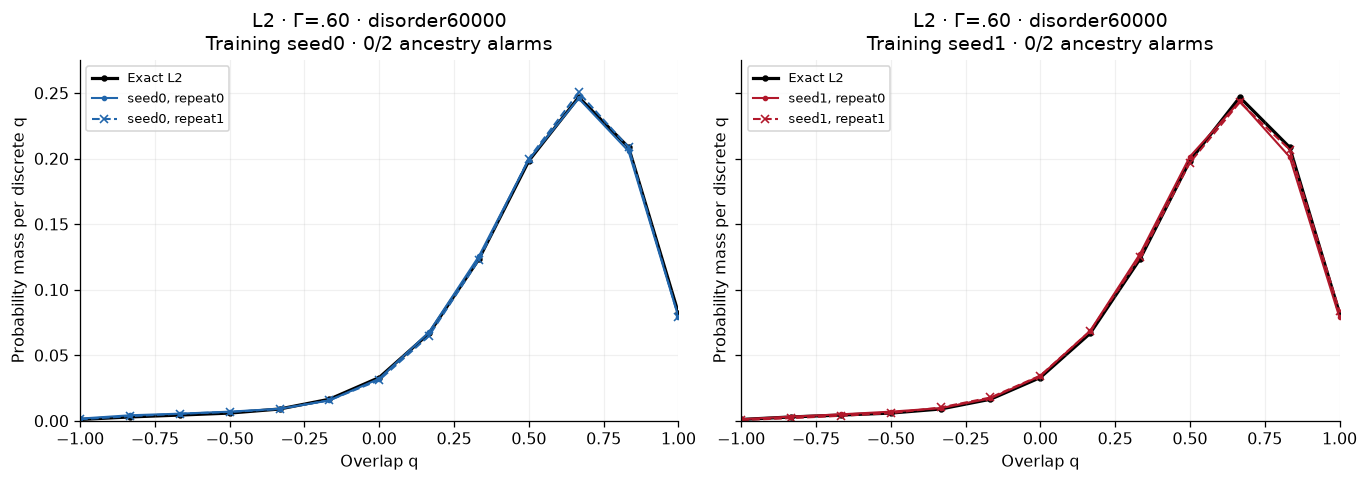

Exact L2 ⟨q²⟩ = 0.410202647; native Δq = 1/6. Final self-learning guides.


| Training seed | Repeat | ⟨q²⟩ | Absolute q² error | TV from exact | Minimum ancestry ESS | Alarm |
| --- | --- | --- | --- | --- | --- | --- |
| 0 | 0 | 0.407827 | 0.002376 | 0.00831 | 85.67 | False |
| 0 | 1 | 0.410509 | 0.000306 | 0.00810 | 96.09 | False |
| 1 | 0 | 0.402823 | 0.007379 | 0.01357 | 92.30 | False |
| 1 | 1 | 0.407825 | 0.002378 | 0.00893 | 76.70 | False |

Seed1 repeat-mean TV from exact: 0.00908; absolute q² error: 0.004879.
Repeat means are descriptive only; no repeat-based uncertainty is plotted.
Raw paths and hashes:
  repeat0: /root/autodl-tmp/self-learning-rbm-20261103-v1/validation/projector/runs/0a1e87fde56876218d74004a.npz | SHA256 17ce3eac7f5d237f60cfb364319f5d8ee2178015d6de4ac19bea3a1c80d3cca4
  repeat1: /root/autodl-tmp/self-learning-rbm-20261103-v1/validation/projector/runs/fdff71e7ee4cfed0b1637240.npz | SHA256 dc2a803e3985479f142b7b0e4f387361f4d32dc49694b011da9afb0472191077


In [10]:
l2_seed_runs=sorted(select('small_exact',L=2,gamma=.6,sample_id=60000,kind='rbm_2'),
                    key=lambda r:(r['task']['training_seed'],r['task']['repeat']))
assert len(l2_seed_runs)==4
assert {(r['task']['training_seed'],r['task']['repeat']) for r in l2_seed_runs} == {
    (seed,repeat) for seed in [0,1] for repeat in [0,1]}
l2_validation=report['supplements']['self-learning-rbm-20261103-v1/validation/summary.json']['record']
l2_exact=l2_validation['exact']
exact_q=np.asarray(l2_exact['q_grid']);exact_mass=np.asarray(l2_exact['mass'])
np.testing.assert_allclose(exact_mass.sum(),1,atol=1e-12)
np.testing.assert_allclose(exact_q**2 @ exact_mass,l2_exact['q2'],atol=1e-12)
reference=l6_contrast[0]
fig,axes=plt.subplots(1,2,figsize=(12,4.3),sharex=True,sharey=True)
l2_repeat_rows=[]
for ax,seed in zip(axes,[0,1]):
    ax.plot(exact_q,exact_mass,'k-',lw=2,marker='o',ms=3,label='Exact L2',zorder=1)
    chosen=[r for r in l2_seed_runs if r['task']['training_seed']==seed]
    for r in chosen:
        t=r['task'];rec=r['record'];mass=np.asarray(rec['mass'])
        for key in ['gamma','kind','walkers','equil','forward','start','delta','cycles']:
            assert t[key]==reference['task'][key],key
        for key in ['numerics','numerics_sha256','sources']:
            assert rec['provenance'][key]==reference['record']['provenance'][key],key
        assert {'raw_sha256','descendant_counts','raw_q_q2_connected_spectrum'} <= set(r['checks'])
        np.testing.assert_allclose(rec['q_grid'],exact_q,atol=1e-12)
        np.testing.assert_allclose(mass.sum(),1,atol=1e-12)
        np.testing.assert_allclose(exact_q**2 @ mass,rec['q2'],atol=1e-12)
        repeat=t['repeat']
        ax.plot(rec['q_grid'],mass,color=COLORS[f'seed{seed}'],ls=['-','--'][repeat],
                marker=['.','x'][repeat],ms=5,lw=1.3,label=f'seed{seed}, repeat{repeat}')
        l2_repeat_rows.append([seed,repeat,f"{rec['q2']:.6f}",
            f"{abs(rec['q2']-l2_exact['q2']):.6f}",f"{.5*np.abs(mass-exact_mass).sum():.5f}",
            f"{r['descendant_ess_min']:.2f}",rec['ancestry_alarm']])
    alarms=sum(r['record']['ancestry_alarm'] for r in chosen)
    ax.set(title=f'L2 · Γ=.60 · disorder60000\nTraining seed{seed} · {alarms}/2 ancestry alarms',
           xlabel='Overlap q',ylabel='Probability mass per discrete q',xlim=(-1,1))
    stamp(ax);ax.legend(fontsize=8)
peak=max(float(exact_mass.max()),max(max(r['record']['mass']) for r in l2_seed_runs))
axes[0].set_ylim(0,1.1*peak)
assert all(max(line.get_ydata())<ax.get_ylim()[1] for ax in axes for line in ax.lines)
show(fig)
print(f"Exact L2 ⟨q²⟩ = {l2_exact['q2']:.9f}; native Δq = 1/6. Final self-learning guides.")
table(['Training seed','Repeat','⟨q²⟩','Absolute q² error','TV from exact','Minimum ancestry ESS','Alarm'],
      l2_repeat_rows)
l2_seed1=[r for r in l2_seed_runs if r['task']['training_seed']==1]
l2_seed1_mean=np.mean([r['record']['mass'] for r in l2_seed1],axis=0)
seed1_saved=next(r for r in l2_validation['rows'] if r['seed']==1)
np.testing.assert_allclose(l2_seed1_mean,seed1_saved['mean']['mass'],atol=1e-12)
np.testing.assert_allclose(.5*np.abs(l2_seed1_mean-exact_mass).sum(),
                           seed1_saved['errors']['histogram_tv'],atol=1e-12)
print(f"Seed1 repeat-mean TV from exact: {seed1_saved['errors']['histogram_tv']:.5f}; "
      f"absolute q² error: {abs(seed1_saved['errors']['q2_error']):.6f}.")
print('Repeat means are descriptive only; no repeat-based uncertainty is plotted.')
print('Raw paths and hashes:')
for r in l2_seed1:
    print(f"  repeat{r['task']['repeat']}: {r['raw_path']} | SHA256 {r['raw_sha256']}")

### An almost-stable energy is not enough
The next comparison averages the two repeats **only to form descriptive
differences**. It does not estimate uncertainty. The x/y distances are divided
by the pre-existing energy and overlap screening tolerances. Values above one
exceed the corresponding screen; values below one do not certify accuracy.

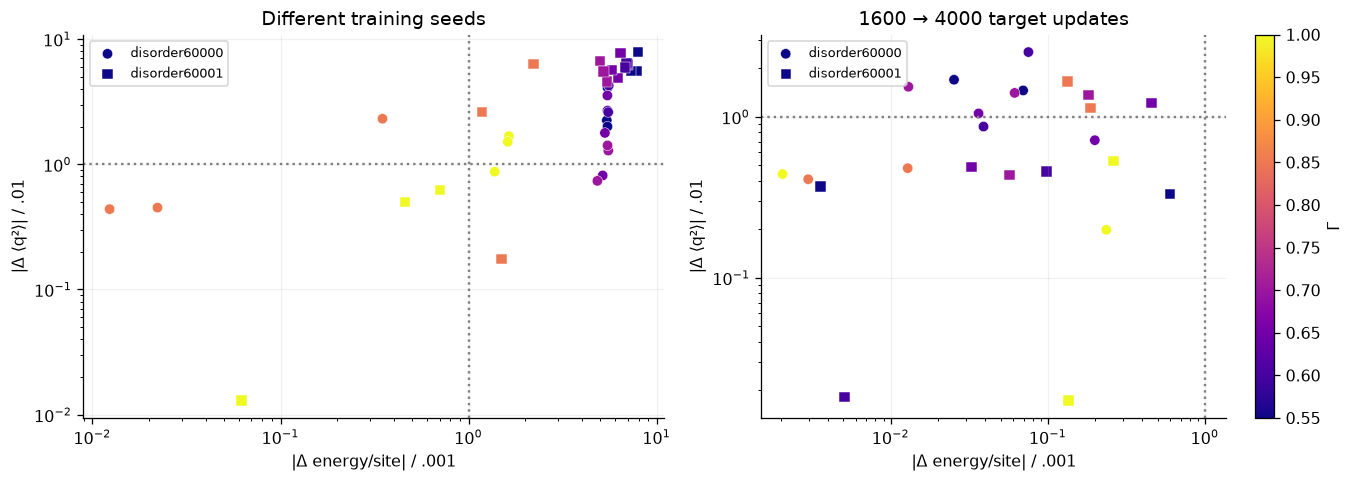

| Comparison | Pairs | Energy screen exceeded | q² screen exceeded | Histogram TV exceeded | Connected spectrum exceeded |
| --- | --- | --- | --- | --- | --- |
| between_seed | 36 | 30/36 | 27/36 | 32/36 | 32/36 |
| last_two_budgets | 24 | 0/24 | 10/24 | 13/24 | 9/24 |

In [11]:
fig,axes=plt.subplots(1,2,figsize=(12,4.3))
metrics=[('energy_per_site_difference',.001),('q2_difference',.01),
         ('histogram_tv',.05),('spectrum_max_tolerance_ratio',1)]
summary=[]
for ax,kind in zip(axes,['between_seed','last_two_budgets']):
    cs=[c for c in report['comparisons'] if c['kind']==kind]
    for disorder,marker in [(60000,'o'),(60001,'s')]:
        chosen=[c for c in cs if c['sample_id']==disorder]
        sc=ax.scatter([c['energy_per_site_difference']/.001 for c in chosen],
                      [c['q2_difference']/.01 for c in chosen],
                      c=[c['gamma'] for c in chosen],vmin=.55,vmax=1,cmap='plasma',
                      marker=marker,s=42,label=f'disorder{disorder}',edgecolor='white',lw=.3)
    ax.axvline(1,color='gray',ls=':');ax.axhline(1,color='gray',ls=':')
    ax.set(xscale='log',yscale='log',xlabel='|Δ energy/site| / .001',ylabel='|Δ ⟨q²⟩| / .01',
           title='Different training seeds' if kind=='between_seed' else '1600 → 4000 target updates')
    ax.legend(fontsize=8);stamp(ax)
    summary.append([kind,len(cs)]+[f"{sum(c[key]>limit for c in cs)}/{len(cs)}" for key,limit in metrics])
fig.colorbar(sc,ax=axes[1],label='Γ')
show(fig)
table(['Comparison','Pairs','Energy screen exceeded','q² screen exceeded',
       'Histogram TV exceeded','Connected spectrum exceeded'],summary)

All 24 last-two-budget comparisons satisfy the energy-distance screen, yet
10 exceed the $q^2$ screen, 13 exceed histogram TV, and nine exceed a
connected-spectrum component screen. All contributing fixed-guide runs
still alarm. Energy stability alone is therefore an inadequate stopping rule.

## 5. Is failure confined to the low-field regime?
The completed .85/1.00 references use the **same measurement budget** as the
lower-field study. Each field has 24 runs: two disorders × two seeds × three
training milestones × two repeats. Every point is a run; horizontal offsets
merely separate markers. Blue/red identify seeds0/1; circles/squares identify
disorders60000/60001. The references are not assumed paramagnetic.

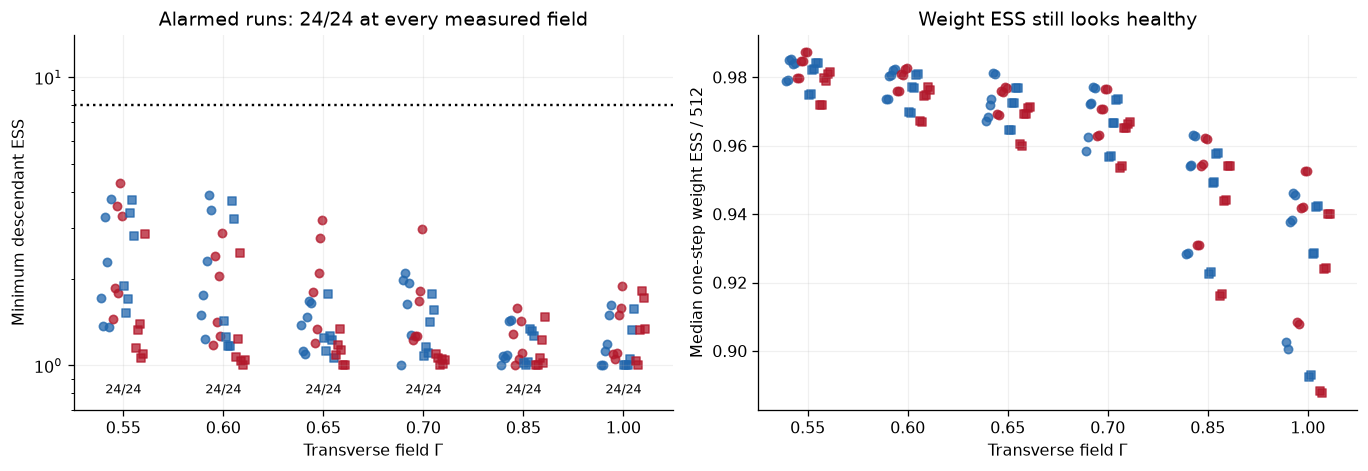

| Γ | Runs | Ancestry alarms | Protocol |
| --- | --- | --- | --- |
| 0.55 | 24 | 24 | 4 populations × 512 walkers, equil16, forward16, 8 cycles |
| 0.6 | 24 | 24 | 4 populations × 512 walkers, equil16, forward16, 8 cycles |
| 0.65 | 24 | 24 | 4 populations × 512 walkers, equil16, forward16, 8 cycles |
| 0.7 | 24 | 24 | 4 populations × 512 walkers, equil16, forward16, 8 cycles |
| 0.85 | 24 | 24 | 4 populations × 512 walkers, equil16, forward16, 8 cycles |
| 1.0 | 24 | 24 | 4 populations × 512 walkers, equil16, forward16, 8 cycles |

In [12]:
all_fields=[.55,.60,.65,.70,.85,1.]
fig,axes=plt.subplots(1,2,figsize=(12,4.2))
for k,gamma in enumerate(all_fields):
    group=sorted([r for r in budget_runs if r['task']['gamma']==gamma],
                 key=lambda r:(r['task']['sample_id'],r['task']['training_seed'],r['target_updates'],r['task']['repeat']))
    assert len(group)==24
    for i,r in enumerate(group):
        x=k+np.linspace(-.22,.22,len(group))[i]
        for ax,key in zip(axes,['descendant_ess_min','weight_ess_fraction_median']):
            ax.scatter(x,r[key],color=COLORS[f"seed{r['task']['training_seed']}"],
                       marker='o' if r['task']['sample_id']==60000 else 's',s=27,alpha=.75)
    axes[0].text(k,.80,'24/24',ha='center',fontsize=8)
axes[0].axhline(8,color='black',ls=':');axes[0].set(yscale='log',ylim=(.7,14),
    ylabel='Minimum descendant ESS',title='Alarmed runs: 24/24 at every measured field')
axes[1].set(ylabel='Median one-step weight ESS / 512',title='Weight ESS still looks healthy')
for ax in axes:ax.set(xticks=range(6),xticklabels=[f'{g:.2f}' for g in all_fields],xlabel='Transverse field Γ');stamp(ax)
show(fig)
table(['Γ','Runs','Ancestry alarms','Protocol'],
      [(g,len([r for r in budget_runs if r['task']['gamma']==g]),
        sum(r['record']['ancestry_alarm'] for r in budget_runs if r['task']['gamma']==g),
        '4 populations × 512 walkers, equil16, forward16, 8 cycles') for g in all_fields])

**The matched-budget reference does not rescue sampling at Γ=.85/1.00.**
This broadens the demonstrated reliability problem; it does not locate a
glass boundary. Warmup schedules also differ: low-field guides traverse
1.50→.75→target, whereas references traverse 1.50→target.

## 6. Iterative feedback: genuine improvement, incomplete rescue
Fixed-guide VMC failure is not automatically failure of a self-learning method.
This section includes the completed **baseline and robust feedback** study:
four disorder/seed contexts, two arms, 12 stints, independent frozen-guide
measurements at stints6/12. The fixed controls are the same hashed baseline
measurements already included in the budget study.

Baseline uses one 1024-walker training population. Robust uses four independent
1024-walker populations, 16-temperature two-copy replica exchange, and bounded
empirical log-density steps. Both receive 1000 likelihood updates per stint.
The intervention changes several ingredients and compute cost together.
Training ancestry and frozen-guide measurement ancestry are distinct checks.
Each training stint's target-collection genealogy precedes that stint's new
likelihood fit; the frozen checkpoint is measured after the fit. A better
training trace is therefore not itself a final-observable convergence test.

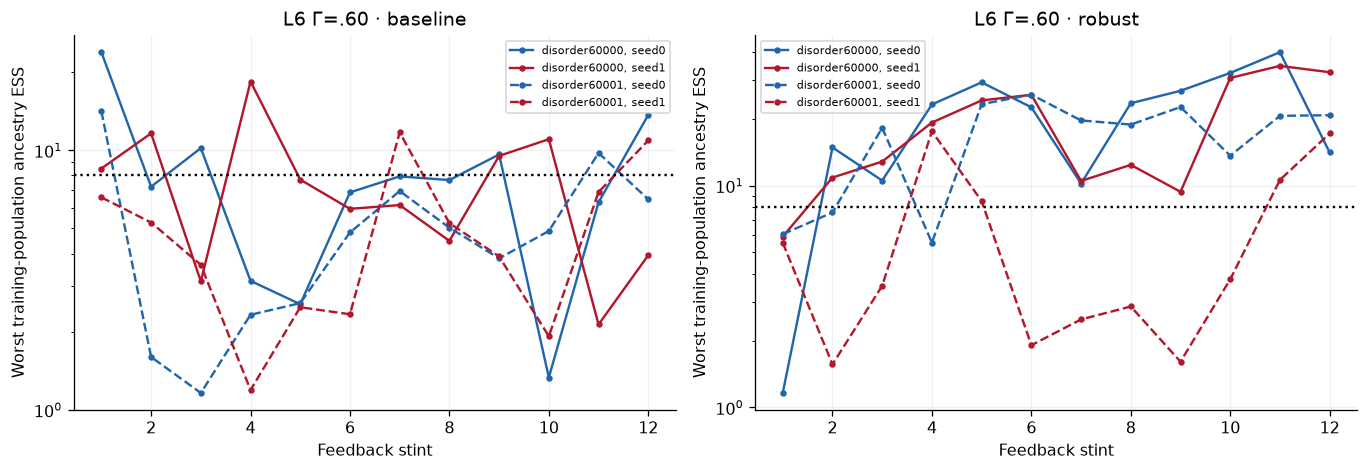

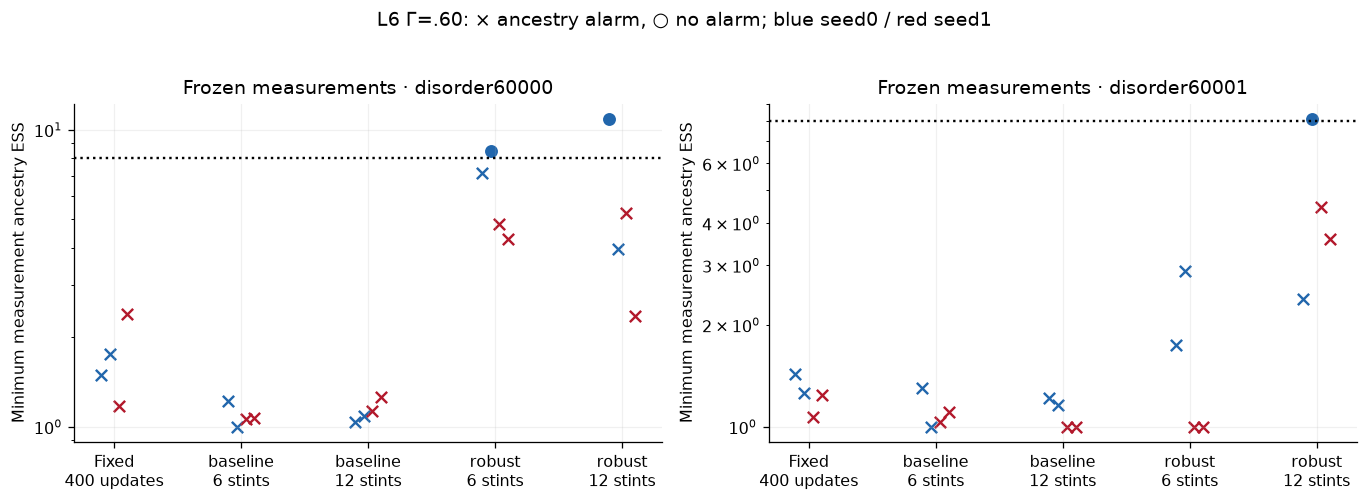

| Frozen guide | Runs | Ancestry alarms |
| --- | --- | --- |
| Fixed, 400 updates | 8 | 8/8 |
| baseline, 6 stints | 8 | 8/8 |
| baseline, 12 stints | 8 | 8/8 |
| robust, 6 stints | 8 | 7/8 |
| robust, 12 stints | 8 | 6/8 |

In [13]:
fig,axes=plt.subplots(1,2,figsize=(12,4.2))
for ax,arm in zip(axes,['baseline','robust']):
    for entry in report['training']:
        if entry['campaign']!='feedback_frontier' or entry['arm']!=arm:continue
        settings=entry['manifest']['settings'];seed=settings['seed'];disorder=settings['sample_id']
        ax.plot([r['stint']+1 for r in entry['rows']],
                [r['minimum_training_lineage_ess'] for r in entry['rows']],
                color=COLORS[f'seed{seed}'],ls='-' if disorder==60000 else '--',marker='.',
                label=f'disorder{disorder}, seed{seed}')
    ax.axhline(8,color='black',ls=':');ax.set(yscale='log',xlabel='Feedback stint',
        ylabel='Worst training-population ancestry ESS',title=f'L6 Γ=.60 · {arm}')
    ax.legend(fontsize=7);stamp(ax)
show(fig)
fig,axes=plt.subplots(1,2,figsize=(12,4.2))
feedback_groups=[('Fixed, 400 updates',[r for r in budget_runs if r['task']['gamma']==.6 and r['target_updates']==400])]
for arm in ['baseline','robust']:
    for stints in [6,12]:
        feedback_groups.append((f'{arm}, {stints} stints',[r for r in runs if r['campaign']=='feedback_frontier'
                                and r['arm']==arm and r['stints']==stints]))
for ax,disorder in zip(axes,[60000,60001]):
    for pos,(label,group) in enumerate(feedback_groups):
        chosen=sorted([r for r in group if r['task']['sample_id']==disorder],
                      key=lambda r:(r['task']['training_seed'],r['task']['repeat']))
        for i,r in enumerate(chosen):
            ax.scatter(pos+(i-1.5)*.07,r['descendant_ess_min'],s=50,
                       marker='x' if r['record']['ancestry_alarm'] else 'o',
                       color=COLORS[f"seed{r['task']['training_seed']}"])
    ax.axhline(8,color='black',ls=':');ax.set(yscale='log',ylabel='Minimum measurement ancestry ESS',
           xticks=range(len(feedback_groups)),xticklabels=[l.replace(', ','\n') for l,g in feedback_groups],
           title=f'Frozen measurements · disorder{disorder}')
    stamp(ax)
fig.suptitle('L6 Γ=.60: × ancestry alarm, ○ no alarm; blue seed0 / red seed1',y=1.03)
show(fig)
table(['Frozen guide','Runs','Ancestry alarms'],
      [(label,len(group),f"{sum(r['record']['ancestry_alarm'] for r in group)}/{len(group)}")
       for label,group in feedback_groups])

Robust training ancestry improves, but its final-stint frozen measurements
still alarm in **6/8** runs (versus **8/8** for baseline). Both successful
ancestry checks remain visible. The original six-stint pilot separately
has 8/8 alarmed measurements; it is retained in the full run ledger.

### Longer feedback and a high-to-low-field curriculum
The later study starts each disorder/seed's three arms from the same hashed
Γ=4 guide: direct reset negatives, direct persistent contrastive divergence
(PCD), or curriculum PCD. All use four 1024-walker training populations and
24×1000 likelihood updates. The curriculum spends 18 stints at higher fields,
then six at .60. Direct arms spend all 24 at .60. Independent measurements
at global stints21 and24 use the same 512-walker/forward16 protocol as before.
These are update-matched, not propagation-cost-matched experiments.

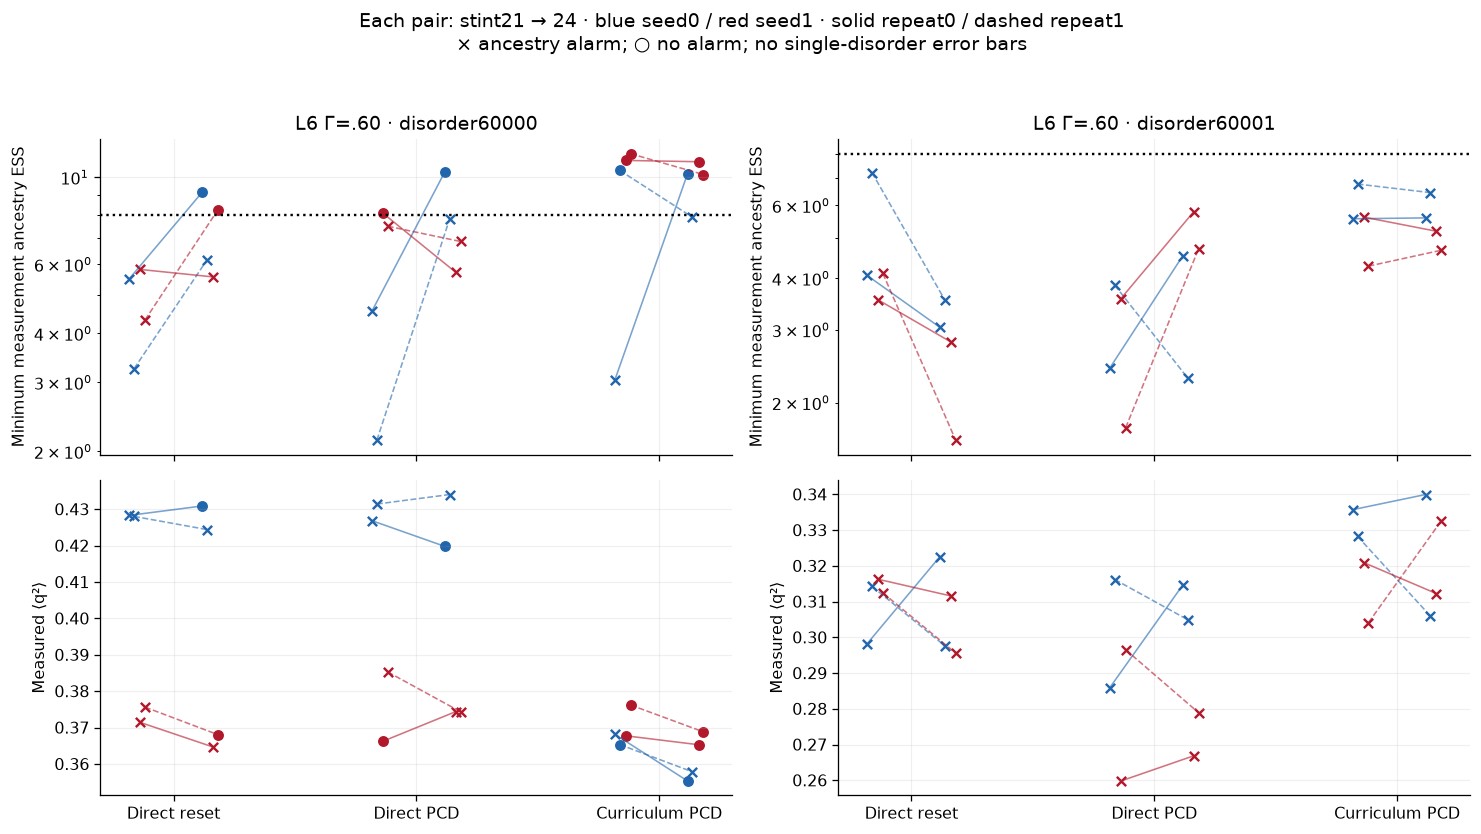

| Arm | Stints | Runs | Ancestry alarms |
| --- | --- | --- | --- |
| direct_reset | 21 | 8 | 8/8 |
| direct_reset | 24 | 8 | 6/8 |
| direct_pcd | 21 | 8 | 7/8 |
| direct_pcd | 24 | 8 | 7/8 |
| curriculum_pcd | 21 | 8 | 5/8 |
| curriculum_pcd | 24 | 8 | 5/8 |

In [14]:
arms=['direct_reset','direct_pcd','curriculum_pcd']
fig,axes=plt.subplots(2,2,figsize=(13,7),sharex=True)
for col,disorder in enumerate([60000,60001]):
    for pos,arm in enumerate(arms):
        for seed in [0,1]:
            for repeat in [0,1]:
                rs=sorted([r for r in runs if r['campaign']=='pcd_curriculum' and r['arm']==arm
                           and r['task']['sample_id']==disorder and r['task']['training_seed']==seed
                           and r['task']['repeat']==repeat],key=lambda r:r['stints'])
                assert [r['stints'] for r in rs]==[21,24]
                x=np.array([pos-.15,pos+.15])+(seed-.5)*.045+(repeat-.5)*.02
                for row,key in [(0,'ess'),(1,'q2')]:
                    y=[r['descendant_ess_min'] if key=='ess' else r['record']['q2'] for r in rs]
                    axes[row,col].plot(x,y,color=COLORS[f'seed{seed}'],ls=['-','--'][repeat],alpha=.6,lw=1)
                    for xx,yy,r in zip(x,y,rs):
                        axes[row,col].scatter(xx,yy,color=COLORS[f'seed{seed}'],s=34,
                            marker='x' if r['record']['ancestry_alarm'] else 'o')
    axes[0,col].axhline(8,color='black',ls=':');axes[0,col].set(yscale='log',
        ylabel='Minimum measurement ancestry ESS',title=f'L6 Γ=.60 · disorder{disorder}')
    axes[1,col].set(ylabel='Measured ⟨q²⟩')
    for ax in axes[:,col]:ax.set(xticks=range(3),xticklabels=['Direct reset','Direct PCD','Curriculum PCD']);stamp(ax)
fig.suptitle('Each pair: stint21 → 24 · blue seed0 / red seed1 · solid repeat0 / dashed repeat1\n'
             '× ancestry alarm; ○ no alarm; no single-disorder error bars',y=1.03)
show(fig)
table(['Arm','Stints','Runs','Ancestry alarms'],
      [(arm,stints,len(rs),f"{sum(r['record']['ancestry_alarm'] for r in rs)}/{len(rs)}")
       for arm in arms for stints in [21,24]
       for rs in [[r for r in runs if r['campaign']=='pcd_curriculum' and r['arm']==arm and r['stints']==stints]]])

Curriculum improves the final genealogy relative to several alternatives,
but **5/8** final measurements still alarm. Direct PCD has **7/8** and direct
reset **6/8** alarms at stint24. The improved runs do not justify saying that
*every* feedback run fails; the unresolved failures and seed/arm dependence
prevent promoting this protocol to reliable low-field production.

## 7. Successful controls and the limits of a size/phase claim
The L2 Γ=.60 self-learning test has an exact interacting reference. All four
final measurements avoid ancestry alarms. The strong-field Γ=4 control also
avoids ancestry alarms in all 24 L2/L6 runs. These controls matter: the
algorithm is capable of working well in some tested settings.

**Protocol mismatch:** strong-field main controls use W=128, equilibration=.5,
forward=.5, and four cycles, with population/time/start variations. Weak-field
runs use much longer forward walking and different guides. Thus the Γ=4
comparison is a successful short-projection control, not a matched causal
demonstration of a glass transition or proof of full strong-field convergence.
Saved strong-field energy/start audits retain residual sensitivity despite
passing ancestry checks; the original numerical qualifications remain false.

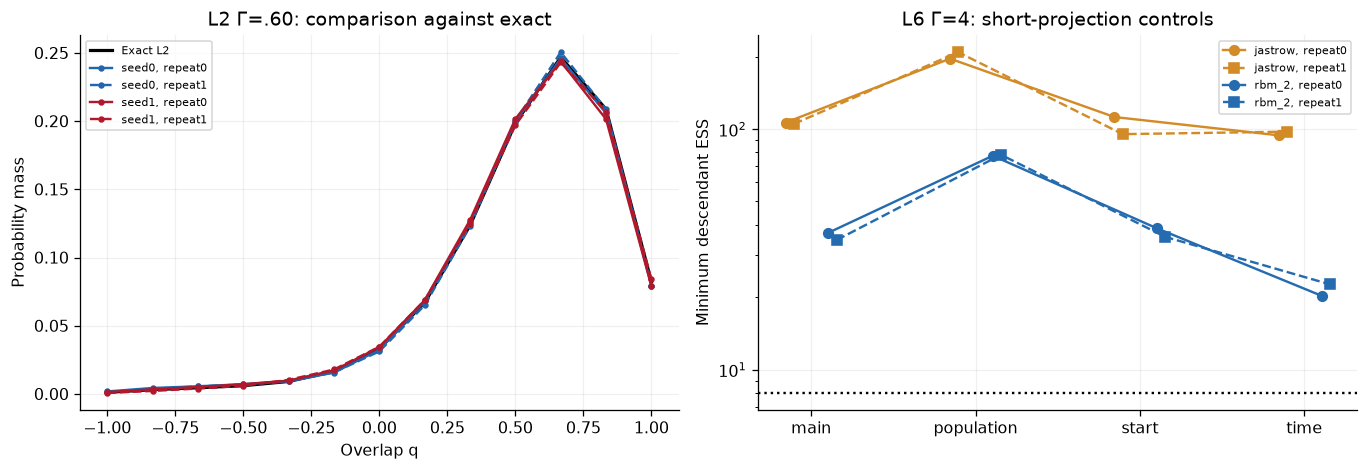

| L2 seed | Histogram TV from exact | |q² error| | Minimum ancestry ESS |
| --- | --- | --- | --- |
| 0 | 0.00697 | 0.00104 | 85.67 |
| 1 | 0.00908 | 0.00488 | 76.70 |

| L6 guide | Audit | W | Equil | Forward | Cycles | Alarms / 2 runs |
| --- | --- | --- | --- | --- | --- | --- |
| jastrow | main | 128 | 0.5 | 0.5 | 4 | 0 |
| jastrow | population | 256 | 0.5 | 0.5 | 4 | 0 |
| jastrow | start | 128 | 0.5 | 0.5 | 4 | 0 |
| jastrow | time | 128 | 1.0 | 1.0 | 4 | 0 |
| rbm_2 | main | 128 | 0.5 | 0.5 | 4 | 0 |
| rbm_2 | population | 256 | 0.5 | 0.5 | 4 | 0 |
| rbm_2 | start | 128 | 0.5 | 0.5 | 4 | 0 |
| rbm_2 | time | 128 | 1.0 | 1.0 | 4 | 0 |

In [15]:
l2=report['supplements']['self-learning-rbm-20261103-v1/validation/summary.json']['record']
fig,axes=plt.subplots(1,2,figsize=(12,4.2))
axes[0].plot(l2['exact']['q_grid'],l2['exact']['mass'],'k-',lw=2,label='Exact L2')
for seed in [0,1]:
    for repeat in [0,1]:
        r=next(r for r in select('small_exact') if r['task']['training_seed']==seed and r['task']['repeat']==repeat)
        axes[0].plot(r['record']['q_grid'],r['record']['mass'],color=COLORS[f'seed{seed}'],
                     ls=['-','--'][repeat],marker='.',label=f'seed{seed}, repeat{repeat}')
axes[0].set(xlabel='Overlap q',ylabel='Probability mass',title='L2 Γ=.60: comparison against exact')
axes[0].legend(fontsize=7);stamp(axes[0])
strong=select('strong_field',L=6)
for kind,offset in [('jastrow',-.13),('rbm_2',.13)]:
    for repeat in [0,1]:
        chosen=[next(r for r in strong if r['task']['kind']==kind and r['task']['audit']==a
                     and r['task']['repeat']==repeat) for a in audits]
        axes[1].plot(np.arange(4)+offset+(repeat-.5)*.05,[r['descendant_ess_min'] for r in chosen],
                     ['o-','s--'][repeat],color=COLORS[kind],label=f'{kind}, repeat{repeat}')
axes[1].axhline(8,color='black',ls=':');axes[1].set(yscale='log',xticks=range(4),xticklabels=audits,
    ylabel='Minimum descendant ESS',title='L6 Γ=4: short-projection controls')
axes[1].legend(fontsize=7);stamp(axes[1]);show(fig)
table(['L2 seed','Histogram TV from exact','|q² error|','Minimum ancestry ESS'],
      [(r['seed'],f"{r['errors']['histogram_tv']:.5f}",f"{abs(r['errors']['q2_error']):.5f}",
        f"{r['minimum_descendant_ess']:.2f}") for r in l2['rows']])
strong_rows=[]
for kind in ['jastrow','rbm_2']:
    for audit in audits:
        rs=[r for r in strong if r['task']['kind']==kind and r['task']['audit']==audit]
        t=rs[0]['task'];strong_rows.append([kind,audit,t['walkers'],t['equil'],t['forward'],
             t['cycles'],sum(r['record']['ancestry_alarm'] for r in rs)])
table(['L6 guide','Audit','W','Equil','Forward','Cycles','Alarms / 2 runs'],strong_rows)

**Failure is already observed at L=4.** The completed two-seed Γ=.60
comparison for disorder60000 shows strong P(q) disagreement (TV=.44798)
and ancestry alarms in three of four runs. L4 therefore cannot serve as a
reliable baseline for claiming an onset of failure at L=6. This is a
disorder-, guide-, and budget-dependent diagnosis, not a universal size threshold.

Separately, the original L4 repaired-production snapshot contains alarms in
seven of 26 records; it excludes the four newly added seed1 projections.
Disorder realizations depend on L, so equal sample IDs across sizes do not
mean identical bonds. L8/L10 have zero physical measurements in the
explicitly audited Monte Carlo scaling campaign.

**No “deep glass” phase identification follows.** Low-field frustration,
seed sensitivity, and lost genealogy motivate a difficult-sampling diagnosis.
Establishing glass order or a phase boundary requires reliable connected
observables, disorder/size scaling, and converged population/time/start tests.
A narrow P(q), a stable energy, or an ancestry alarm alone is insufficient.

## 8. Provenance, retained failures, and complete run ledger
The extraction hashes every raw NPZ and JSON record; recomputes ancestry
ESS/lineage maxima from descendant counts; checks finite diagnostics and
histogram normalization/moments; and replays q, q², and connected spectra
from raw tags/counts wherever those observables are recorded. Strong-field
controls receive raw-hash and count/ancestry checks; no unperformed histogram
replay is claimed.

Feedback extraction hashes raw targets, input/output models, and fit traces,
replays collection-period ancestry, verifies common starting models within
paired arms, and matches measurement-guide hashes to training milestones.
Bond fingerprints are reconstructed from the archived generator and seeds;
raw GFMC files do not independently store the Hamiltonian bond arrays.
`replay_verified=False` in original simulation records is preserved; this
report's post-hoc checks are recorded separately and do not qualify a ground state.

In [16]:
import html
assert len({r['path'] for r in runs})==len(runs)
assert not report['duplicate_raw_files']
assert all('descendant_counts' in r['checks'] for r in runs)
assert all(not r['record']['ground_state_qualified'] for r in runs)
assert all(r['record']['ancestry_alarm']==(r['descendant_ess_min']<8 or r['largest_lineage_max']>.5) for r in runs)
print('Unique raw measurement files:',len(runs))
print('Hash-linked reused controls:',len(report['reused_controls']))
print('Verified paired initial-model groups:',len(report['matched_initial_models']))
print('Verified extraction helper sources:',len(report['helper_sources']))
print('Evidence SHA256:',hashes['report.json'])
print('Extractor SHA256:',report['extractor_sha256'])
table(['Campaign','Raw root','Selection'],[(c['name'],c['root'],c['selection']) for c in report['campaigns']])
training_rows=[]
for t in report['training']:
    training_rows.append([t['campaign'],t['arm'],t['context'],len(t['rows']),
                          sum(r['training_ancestry_alarm'] for r in t['rows'])])
table(['Training campaign','Arm','Context','Stints','Training ancestry alarms'],training_rows)
failures=report['failures']
replay_failure=report['supplements']['rbm-repair-20261103-v1/failed_start_reproduction.json']['record']
print('Preserved old numerical failure:',replay_failure['original']['error'])
print('Historical failure-containing artifacts:',len(failures))
display(HTML('<details><summary>Retained historical execution errors (verbatim artifacts)</summary><pre>'+
             html.escape(json.dumps(failures,indent=2))+'</pre></details>'))
headers=['Campaign / arm / budget','L','Γ','Disorder','Seed','Repeat','W','Equil / forward',
         'q²','ESS min','Max lineage','Alarm','Raw / model hash']
body=[]
for r in sorted(runs,key=lambda r:r['path']):
    t=r['task'];model=r['record'].get('provenance',{}).get('model_sha256',r['record'].get('checkpoint_sha256',''))
    values=[f"{r['campaign']} / {r['arm'] or '—'} / {r['target_updates'] or r['stints'] or '—'}",
            t['L'],t['gamma'],t['sample_id'],t.get('training_seed',0),t['repeat'],t['walkers'],
            f"{t['equil']} / {t['forward']}",f"{r['record']['q2']:.6f}",f"{r['descendant_ess_min']:.3f}",
            f"{r['largest_lineage_max']:.3f}",r['record']['ancestry_alarm'],
            r['raw_sha256'][:12]+' / '+model[:12]]
    body.append('<tr>'+''.join('<td>'+html.escape(str(v))+'</td>' for v in values)+'</tr>')
display(HTML('<details><summary>All '+str(len(runs))+' measured runs, including every ancestry alarm</summary>'+
             '<table><thead><tr>'+''.join('<th>'+h+'</th>' for h in headers)+'</tr></thead><tbody>'+
             ''.join(body)+'</tbody></table></details>'))
print('Full paths, SHA256 values, tasks, provenance, ancestry arrays, spectra, distributions, and statuses are in report.json.gz.')

Unique raw measurement files: 320
Hash-linked reused controls: 8
Verified paired initial-model groups: 8
Verified extraction helper sources: 3
Evidence SHA256: 8e130f4b3fca7ccc8c53894c053616e0b9b4ba77288816781d0b97fc16b688a7
Extractor SHA256: 8045b0590c73b5642dd0b636c6800ae5e637a27a57d990106b7ef99eb8f8d1fd


| Campaign | Raw root | Selection |
| --- | --- | --- |
| fixed_low | /root/autodl-tmp/l6-convergence-20261103-v1/results | **/runs/*.json |
| fixed_extension | /root/autodl-tmp/extended-rbm-20261103-v1/results | **/runs/*.json |
| reference_fields | /root/autodl-tmp/l6-reference-fields-20261103-v1/results | **/runs/*.json |
| ancestry_controls | /root/autodl-tmp/ancestry-diagnostic-20261103-v1/results | **/runs/*.json |
| production_audits | /root/autodl-tmp/disorder-scaling-repaired-20261103-v2/results | projector/runs/*.json |
| feedback_original | /root/autodl-tmp/self-learning-l6-20261103-v1/results | projector/**/runs/*.json |
| feedback_frontier | /root/autodl-tmp/self-learning-frontier-20261103-v1/scaling/L6 | measurements/**/runs/*.json |
| pcd_curriculum | /root/autodl-tmp/l6-pcd-curriculum-20261103-v1/results | measurements/**/runs/*.json |
| small_exact | /root/autodl-tmp/self-learning-rbm-20261103-v1/validation | projector/runs/*.json |
| strong_field | /root/autodl-tmp/rbm-repair-20261103-v1/validation | projector/*.json |

| Training campaign | Arm | Context | Stints | Training ancestry alarms |
| --- | --- | --- | --- | --- |
| feedback_frontier | baseline | L6_s60000_g0p6_rbm_2_anneal_seed0 | 12 | 8 |
| feedback_frontier | baseline | L6_s60000_g0p6_rbm_2_anneal_seed1 | 12 | 7 |
| feedback_frontier | baseline | L6_s60001_g0p6_rbm_2_anneal_seed0 | 12 | 10 |
| feedback_frontier | baseline | L6_s60001_g0p6_rbm_2_anneal_seed1 | 12 | 10 |
| feedback_frontier | robust | L6_s60000_g0p6_rbm_2_anneal_seed0 | 12 | 1 |
| feedback_frontier | robust | L6_s60000_g0p6_rbm_2_anneal_seed1 | 12 | 1 |
| feedback_frontier | robust | L6_s60001_g0p6_rbm_2_anneal_seed0 | 12 | 3 |
| feedback_frontier | robust | L6_s60001_g0p6_rbm_2_anneal_seed1 | 12 | 8 |
| pcd_curriculum | curriculum_pcd | L6_s60000_g0p6_rbm_2_anneal_seed0 | 24 | 12 |
| pcd_curriculum | curriculum_pcd | L6_s60000_g0p6_rbm_2_anneal_seed1 | 24 | 11 |
| pcd_curriculum | curriculum_pcd | L6_s60001_g0p6_rbm_2_anneal_seed0 | 24 | 13 |
| pcd_curriculum | curriculum_pcd | L6_s60001_g0p6_rbm_2_anneal_seed1 | 24 | 12 |
| pcd_curriculum | direct_pcd | L6_s60000_g0p6_rbm_2_anneal_seed0 | 24 | 5 |
| pcd_curriculum | direct_pcd | L6_s60000_g0p6_rbm_2_anneal_seed1 | 24 | 5 |
| pcd_curriculum | direct_pcd | L6_s60001_g0p6_rbm_2_anneal_seed0 | 24 | 6 |
| pcd_curriculum | direct_pcd | L6_s60001_g0p6_rbm_2_anneal_seed1 | 24 | 5 |
| pcd_curriculum | direct_reset | L6_s60000_g0p6_rbm_2_anneal_seed0 | 24 | 6 |
| pcd_curriculum | direct_reset | L6_s60000_g0p6_rbm_2_anneal_seed1 | 24 | 4 |
| pcd_curriculum | direct_reset | L6_s60001_g0p6_rbm_2_anneal_seed0 | 24 | 7 |
| pcd_curriculum | direct_reset | L6_s60001_g0p6_rbm_2_anneal_seed1 | 24 | 4 |

Preserved old numerical failure: RuntimeError('walker weights left the positive reals')
Historical failure-containing artifacts: 2


Campaign / arm / budget,L,Γ,Disorder,Seed,Repeat,W,Equil / forward,q²,ESS min,Max lineage,Alarm,Raw / model hash
ancestry_controls / — / —,6,0.6,60000,0,1,512,16.0 / 8.0,0.434208,2.759,0.584,True,bb11e946a484 / 14634926ff6d
ancestry_controls / — / —,6,0.55,60000,0,0,2048,16.0 / 16.0,0.483645,3.342,0.540,True,71dac7ed26c9 / 6597ae06ba46
ancestry_controls / — / —,6,0.6,60000,0,1,512,16.0 / 16.0,0.415751,1.309,0.871,True,580888e28e7d / 14634926ff6d
ancestry_controls / — / —,6,0.6,60000,0,0,512,16.0 / 8.0,0.421650,2.078,0.686,True,347c390ddb4d / 14634926ff6d
ancestry_controls / — / —,6,0.55,60000,0,1,512,16.0 / 8.0,0.477129,3.035,0.566,True,a9a2fdf8d846 / 6597ae06ba46
ancestry_controls / — / —,6,0.55,60000,0,0,512,16.0 / 16.0,0.475075,2.291,0.648,True,38a831c6c722 / 6597ae06ba46
ancestry_controls / — / —,6,0.55,60000,0,1,2048,16.0 / 16.0,0.469702,2.000,0.705,True,98fc6c6f21b4 / 6597ae06ba46
ancestry_controls / — / —,6,0.55,60000,0,1,512,16.0 / 16.0,0.484328,1.095,0.955,True,852c6b94d050 / 6597ae06ba46
ancestry_controls / — / —,6,0.6,60000,0,0,512,16.0 / 16.0,0.433432,1.194,0.914,True,73e892d867e5 / 14634926ff6d
ancestry_controls / — / —,6,0.55,60000,0,0,512,16.0 / 8.0,0.494984,8.192,0.289,False,f3783294b3b3 / 6597ae06ba46


Full paths, SHA256 values, tasks, provenance, ancestry arrays, spectra, distributions, and statuses are in report.json.gz.


## Conclusion suitable for reporting

> **The tested Monte Carlo protocol is already unreliable for L=4
> (N=48), Γ=.60, disorder60000.** Across training seeds, repeat-mean
> ⟨q²⟩ changes from 0.32594 to 0.16535, histogram TV is .44798, and
> three of four runs have ancestry alarms. Stable repeats within seed0
> did not establish a reliable P(q), and these data do not determine
> which seed is closer to the ground-state result.
>
> **L=6 (N=108) also remains unreliable under the tested budgets.**
> Fixed-guide RBM simulations at Γ=.55–.70 exhibit severe genealogical
> collapse across all 96 tested
> training-budget/seed/repeat runs, despite healthy one-step weight ESS.
> Seed and budget dependence persists in overlap distributions and connected
> observables. Population/time audits and self-learning improvements do not
> consistently remove the failure; the strongest curriculum still has five
> alarmed final runs out of eight. This supports a finite-budget sampling
> breakdown in the investigated low-field regime. **It rules out treating
> L4 as a demonstrated reliable baseline, but does not establish a
> universal size threshold or identify a deep-glass phase.**

The Γ=.85/1.00 matched-budget references also alarm (48/48); Γ=4 and L2
controls show successful finite checks under different settings. Missing
L8/L10 measurements are coverage gaps. All claims refer to the archived
snapshot displayed at the top, not to a live campaign monitor.